In [12]:
import pandas as pd
import numpy as np
from scipy.stats import gaussian_kde
import sys
from pathlib import Path

project_dir = Path.cwd()
if not (project_dir / "plot_style.py").exists():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
from plot_style import *

# **Test Mass/Age/Luminosity Distribution**

## **TEST AS dnuAsf INSTEAD**

## **TEST dnuAsf v L v dnuAsf+L**

## **COMPARE TO WILL+26**

In [ ]:
break

## new plot style vstack of 3 with low-alpha overplot of willett distribution ##

In [ ]:
sub_lum_data = pd.read_csv("./TESTING_LUMvDNU_lum.csv")
sub_dnu_data = pd.read_csv("./TESTING_LUMvDNU_dnu.csv")
sub_both_data = pd.read_csv("./TESTING_LUMvDNU_both.csv")
w26_data = pd.read_csv("./TESTING_LUMvDNU_w26.csv")

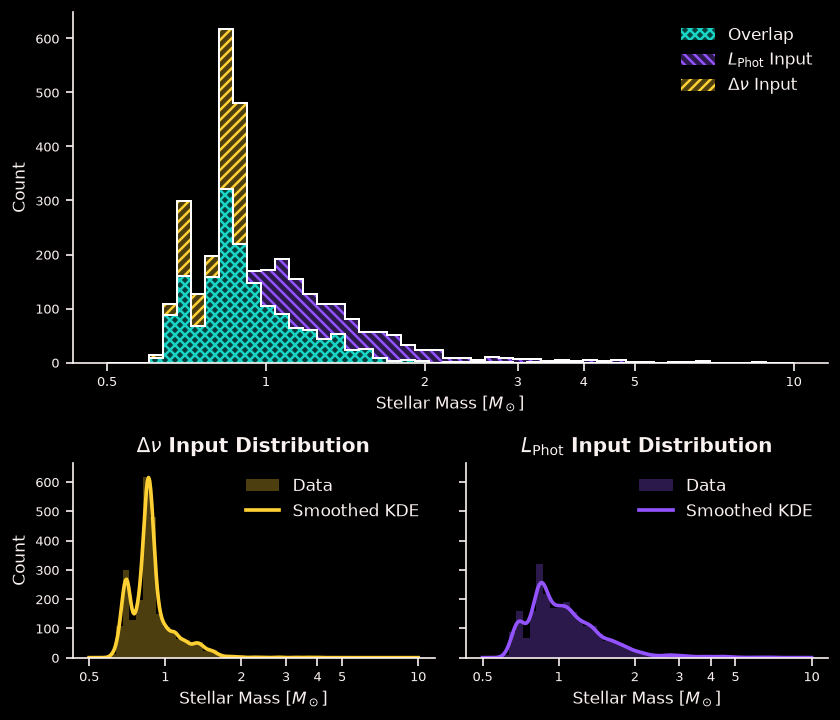

In [ ]:
dark()

fig, axd = plt.subplot_mosaic(
    [["top", "top"],
     ["bottom_left", "bottom_right"]],
    figsize=(7, 6),
    gridspec_kw={"height_ratios": [1.8, 1]},
    constrained_layout=True
)

# Set vertical padding (h_pad) and horizontal padding (w_pad) in inches
fig.get_layout_engine().set(h_pad=0.1, w_pad=0.1)


# Link y-axes of the two bottom plots before plotting
axd["bottom_right"].sharey(axd["bottom_left"])

mass_edges = np.geomspace(0.5, 10, num=50)
widths = np.diff(mass_edges)
tick_positions = [0.5, 1, 2, 3, 4, 5, 10]
tick_names = ["0.5", "1", "2", "3", "4", "5", "10"]

# Optional: make hatch lines slightly thicker so their colours pop on black
plt.rcParams["hatch.linewidth"] = 1.5

# --- TOP PLOT: Translucent Fill + Solid Coloured Hatching ---
counts_lum, _ = np.histogram(sub_lum_data["massfin"], bins=mass_edges)
counts_dnu, _ = np.histogram(sub_dnu_data["massfin"], bins=mass_edges)
overlap = np.minimum(counts_lum, counts_dnu)

lum_only = counts_lum - overlap
dnu_only = counts_dnu - overlap

ax_top = axd["top"]
fill_alpha = 0.3  # Adjust fill transparency independently (0 = transparent, 1 = solid)

# 1. Overlap region
ax_top.bar(mass_edges[:-1], overlap, width=widths, align="edge",
           facecolor=to_rgba(p1, fill_alpha), edgecolor=p1, linewidth=0, hatch="xxxx",
           zorder=1, label=r"Overlap")

# 2. L_Phot-only region
ax_top.bar(mass_edges[:-1], lum_only, bottom=overlap, width=widths, align="edge",
           facecolor=to_rgba(p2, fill_alpha), edgecolor=p2, linewidth=0, hatch=r"\\\\",
           zorder=2, label=r"$L_\mathrm{Phot}$ Input")

# 3. Δν-only region
ax_top.bar(mass_edges[:-1], dnu_only, bottom=overlap, width=widths, align="edge",
           facecolor=to_rgba(p3, fill_alpha), edgecolor=p3, linewidth=0, hatch="////",
           zorder=3, label=r"$\Delta\nu$ Input")

# Outer white outlines around each full distribution
ax_top.stairs(counts_lum, mass_edges, baseline=0, color="#FFFFFF", linewidth=1.2, zorder=4)
ax_top.stairs(counts_dnu, mass_edges, baseline=0, color="#FFFFFF", linewidth=1.2, zorder=4)

ax_top.set_ylabel("Count")
ax_top.set_xlabel(r"Stellar Mass [$M_\odot$]")
ax_top.set_xscale("log")
ax_top.set_xticks(tick_positions, labels=tick_names)
ax_top.minorticks_off()
ax_top.legend(loc="upper right")

# --- HELPER FUNCTION: Smooth KDE Scaled to Raw Counts ---
def plot_smoothed_counts(ax, data, color, title, bw=0.15):
    valid = data[(data >= 0.5) & (data <= 10)]
    log_data = np.log10(valid)
    
    # Fit Gaussian KDE in log10-space
    kde = gaussian_kde(log_data, bw_method=bw)
    
    # Plot raw count histogram
    ax.hist(valid, bins=mass_edges, color=color, alpha=0.3, label="Data")
    
    # Constant bin width in log10-space
    dlog10 = np.diff(np.log10(mass_edges))[0]
    
    # Evaluate KDE on a smooth log-spaced grid and scale to expected counts per bin
    x_grid = np.geomspace(0.5, 10, 300)
    smoothed_counts = kde(np.log10(x_grid)) * len(valid) * dlog10
    
    ax.plot(x_grid, smoothed_counts, color=color, lw=2.2, label="Smoothed KDE", marker="")
    
    ax.set_title(title)
    ax.set_xlabel(r"Stellar Mass [$M_\odot$]")
    ax.set_xscale("log")
    ax.set_xticks(tick_positions, labels=tick_names)
    ax.minorticks_off()
    ax.legend(loc="upper right")
    
    # Return the peak height of the KDE curve
    return np.max(smoothed_counts)

# --- BOTTOM SUBPLOTS ---
peak_dnu = plot_smoothed_counts(axd["bottom_left"], sub_dnu_data["massfin"], p3, r"$\Delta\nu$ Input Distribution", bw=0.15)
axd["bottom_left"].set_ylabel("Count")

peak_lum = plot_smoothed_counts(axd["bottom_right"], sub_lum_data["massfin"], p2, r"$L_\mathrm{Phot}$ Input Distribution", bw=0.15)
axd["bottom_right"].tick_params(labelleft=False)

# Set shared y-limit using the highest KDE peak + padding
axd["bottom_left"].set_ylim(0, max(peak_dnu, peak_lum) + 50)

plt.savefig("./figures/TESTING_LUMvDNU_massdist.png", dpi=200)
plt.show()


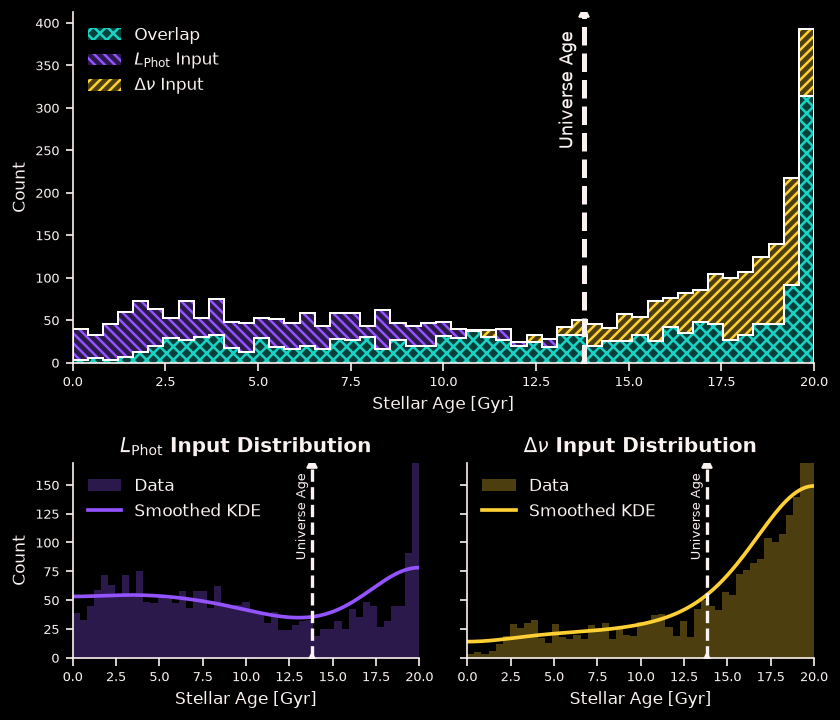

In [ ]:
fig, axd = plt.subplot_mosaic(
    [["top", "top"],
     ["bottom_left", "bottom_right"]],
    figsize=(7, 6),
    gridspec_kw={"height_ratios": [1.8, 1]},
    constrained_layout=True
)

# Set vertical padding (h_pad) and horizontal padding (w_pad) in inches
fig.get_layout_engine().set(h_pad=0.1, w_pad=0.1)

# Link y-axes of the two bottom plots before plotting
axd["bottom_right"].sharey(axd["bottom_left"])

age_edges = np.linspace(0, 20, 50)
widths = np.diff(age_edges)

# Optional: make hatch lines slightly thicker so their colours pop on black
plt.rcParams["hatch.linewidth"] = 1.5

# Convert ages to Gyr
age_lum = sub_lum_data["age"] / 1e3
age_dnu = sub_dnu_data["age"] / 1e3

# --- TOP PLOT: Translucent Fill + Solid Coloured Hatching ---
counts_lum, _ = np.histogram(age_lum, bins=age_edges)
counts_dnu, _ = np.histogram(age_dnu, bins=age_edges)
overlap = np.minimum(counts_lum, counts_dnu)

lum_only = counts_lum - overlap
dnu_only = counts_dnu - overlap

ax_top = axd["top"]
fill_alpha = 0.3  # Adjust fill transparency independently (0 = transparent, 1 = solid)

# 1. Overlap region
ax_top.bar(age_edges[:-1], overlap, width=widths, align="edge",
           facecolor=to_rgba(p1, fill_alpha), edgecolor=p1, linewidth=0, hatch="xxx",
           zorder=1, label=r"Overlap")

# 2. L_Phot-only region
ax_top.bar(age_edges[:-1], lum_only, bottom=overlap, width=widths, align="edge",
           facecolor=to_rgba(p2, fill_alpha), edgecolor=p2, linewidth=0, hatch=r"\\\\",
           zorder=2, label=r"$L_\mathrm{Phot}$ Input")

# 3. Δν-only region
ax_top.bar(age_edges[:-1], dnu_only, bottom=overlap, width=widths, align="edge",
           facecolor=to_rgba(p3, fill_alpha), edgecolor=p3, linewidth=0, hatch="////",
           zorder=3, label=r"$\Delta\nu$ Input")

# Full outer white borders using stairs
ax_top.stairs(counts_lum, age_edges, baseline=0, color="#FFFFFF", linewidth=1.2, zorder=4)
ax_top.stairs(counts_dnu, age_edges, baseline=0, color="#FFFFFF", linewidth=1.2, zorder=4)

# Universe Age marker
ax_top.axvline(13.8, ls="--", color=cream, lw=3, zorder=5)
ax_top.text(13.6, 390, "Universe Age", rotation=90, ha="right", va="top", color=cream, fontsize=11)

ax_top.set_xlabel("Stellar Age [Gyr]")
ax_top.set_ylabel("Count")
ax_top.set_xlim(0, 20)
ax_top.legend(loc="upper left")

# --- HELPER FUNCTION: Smooth KDE Scaled to Raw Counts (Linear Space) ---
def plot_smoothed_counts(ax, data, color, title, bw=0.15):
    valid = data[(data >= 0) & (data <= 20)]
    
    # Reflect data across 0 and 20 Gyr to prevent edge drop-off
    reflected = np.concatenate([valid, -valid, 40 - valid])
    kde = gaussian_kde(reflected, bw_method=bw)
    
    # Plot raw count histogram using age_edges
    ax.hist(valid, bins=age_edges, color=color, alpha=0.3, label="Data", zorder=1)
    
    # Constant bin width in Gyr
    d_age = widths[0]
    
    # Evaluate KDE on a smooth linear grid (multiply by 3 to account for reflected copies)
    x_grid = np.linspace(0, 20, 300)
    smoothed_counts = kde(x_grid) * 3 * len(valid) * d_age
    
    ax.plot(x_grid, smoothed_counts, color=color, lw=2.2, label="Smoothed KDE", zorder=2, marker="")
    ax.axvline(13.8, ls="--", color=cream, lw=2, zorder=3)
    ax.text(13.6, 160, "Universe Age", rotation=90, ha="right", va="top", color=cream, fontsize=8)
    
    ax.set_title(title)
    ax.set_xlabel("Stellar Age [Gyr]")
    ax.set_xlim(0, 20)
    ax.legend(loc="upper left")
    
    # Return the peak height of the KDE curve
    return np.max(smoothed_counts)

# --- BOTTOM SUBPLOTS (Using age_dnu and age_lum in Gyr) ---
peak_dnu = plot_smoothed_counts(axd["bottom_right"], age_dnu, p3, r"$\Delta\nu$ Input Distribution", bw=0.15)
axd["bottom_left"].set_ylabel("Count")

peak_lum = plot_smoothed_counts(axd["bottom_left"], age_lum, p2, r"$L_\mathrm{Phot}$ Input Distribution", bw=0.15)
axd["bottom_right"].tick_params(labelleft=False)

# Set shared y-limit using the highest KDE peak + padding
axd["bottom_left"].set_ylim(0, max(peak_dnu, peak_lum) + 20)

plt.savefig("./figures/TESTING_LUMvDNU_agedist.png", dpi=200)
plt.show()


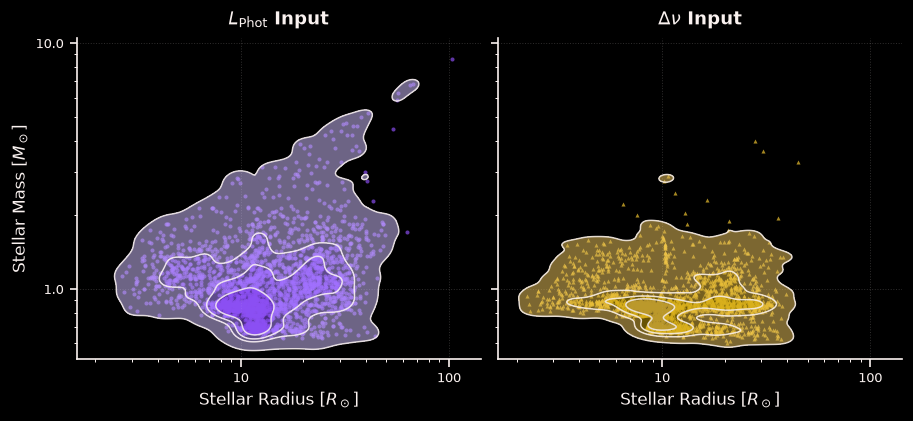

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.4), sharex=True, sharey=True, constrained_layout=True)

# Helper function to keep styling consistent and high-contrast
def plot_mass_radius_kde(ax, data, color, title, marker):
    # 1. Scatter points: slightly larger size and higher contrast
    ax.scatter(
        data["radPhot"],
        data["massfin"],
        color=color,
        alpha=0.65,
        marker=marker,
        s=6,
        linewidths=0,
        zorder=1,
    )
    
    # 2. Filled KDE contours
    sns.kdeplot(
        data=data,
        x="radPhot",
        y="massfin",
        ax=ax,
        color=color,
        fill=True,
        alpha=0.55,
        levels=5,
        thresh=0.01,
        bw_adjust=0.7,
        log_scale=True,
        zorder=2,
    )
    
    # 3. Crisp contour outlines in warm white (`light`) so density tiers are distinct
    sns.kdeplot(
        data=data,
        x="radPhot",
        y="massfin",
        ax=ax,
        color=cream,
        fill=False,
        linewidths=0.9,
        alpha=0.85,
        levels=5,
        thresh=0.01,
        bw_adjust=0.7,
        log_scale=True,
        zorder=3,
    )
    
    ax.set_title(title, fontsize=11, pad=8)
    ax.set_xlabel(r"Stellar Radius [$R_\odot$]")
    ax.grid(True, which="major", linestyle=":", color=cream, alpha=0.18, zorder=0)

# Left panel: L_Phot Input (circles)
plot_mass_radius_kde(axes[0], sub_lum_data, p2, r"$L_\mathrm{Phot}$ Input", marker="o")
axes[0].set_ylabel(r"Stellar Mass [$M_\odot$]")

# Right panel: Δν Input (triangles)
plot_mass_radius_kde(axes[1], sub_dnu_data, p3, r"$\Delta\nu$ Input", marker="^")

# Format log axes with clean readable numbers instead of 10^0
axes[0].set_xscale("log")
axes[0].set_yscale("log")
for ax in axes:
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_major_formatter(ScalarFormatter())

plt.savefig("./figures/TESTING_LUMvDNU_massrad.png", dpi=200)
plt.show()
